In [19]:
import numpy as np
import os
import tensorflow as tf
import cv2
import json
import matplotlib.pyplot as plt
import pandas as pd

print("Hello world.")

Hello world.


In [20]:
import os
import json
import numpy as np
import cv2

def create_mask(json_file, image_shape):
    if json_file is None or not os.path.exists(json_file):
        return None
    try:
        with open(json_file, 'r') as f:
            data = json.load(f)
    except:
        return None
    if 'shapes' not in data or data['shapes'] is None:
        return None

    mask = np.zeros(image_shape[:2], dtype=np.uint8)

    try:
        for shape in data['shapes']:
            points = np.array(shape.get('points', []), dtype=np.int32)
            if len(points) > 2:
                cv2.fillPoly(mask, [points], 255)
    except:
        return None

    return mask


def find_image_file(base_name, image_path):
    """Find the correct image file (.jpg, .JPG, .jpeg, .JPEG, .png)"""
    exts = [".jpg", ".JPG", ".jpeg", ".JPEG", ".png"]
    for ext in exts:
        file_path = os.path.join(image_path, base_name + ext)
        if os.path.exists(file_path):
            return file_path
    return None

print("Hello world")

Hello world


In [21]:
train_images, valid_images, test_images  = [], [], []
train_masks, valid_masks, test_masks = [], [] , []


image_path = "/kaggle/input/malabar-dataset/Malabar_Dataset_Original_Data/Malabar_Dataset/Downy-Mildew(240)"
json_path = "/kaggle/input/malabar-dataset-annotated-json-files/annotated_json_files/Downy-Mildew(240)/affected_region"
split_file = pd.read_csv("/kaggle/input/malabar-dataset/downy_mildew_split.csv")


for i in range(0, len(split_file)):
    used_for = split_file.iloc[i]["used_for"]
    image_no = split_file.iloc[i]["image_no"]
    base_name = f"Downy-Mildew ({image_no})"

    json_file = os.path.join(json_path, base_name + ".json")

    # --- FIND REAL IMAGE FILE ---
    image_file = find_image_file(base_name, image_path)
    if image_file is None:
        print(f"Image missing: {base_name}")
        continue

    image = cv2.imread(image_file)
    if image is None:
        print(f"Failed to read: {image_file}")
        continue

    mask = create_mask(json_file, image.shape)
    if mask is None:
        print(f"Mask skipped: {json_file}")
        continue

    if used_for == "training":
        train_images.append(image)
        train_masks.append(mask)
    elif used_for == "validation":
        valid_images.append(image)
        valid_masks.append(mask)
    else:
        test_images.append(image)
        test_masks.append(mask)





print(len(train_images), len(train_masks))
print(len(valid_images), len(valid_masks))
print(len(test_images), len(test_masks))

192 192
24 24
24 24


In [22]:
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
import numpy as np

# Preprocess images and masks
image_size = (256, 256)

def preprocess_data(images, masks):
    images_resized = [cv2.resize(img, image_size) for img in images]
    masks_resized = [cv2.resize(mask, image_size) for mask in masks]
    
    images_array = np.array(images_resized) / 255.0
    masks_array = np.array(masks_resized) / 255.0
    
    images_array = images_array.astype(np.float32)
    masks_array = masks_array.astype(np.float32)
    
    masks_array = np.expand_dims(masks_array, axis=-1)  # Ensure correct shape
    
    return images_array, masks_array


X_test, Y_test = preprocess_data(test_images, test_masks)
print("Hello world.")

Hello world.


In [23]:
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt
import cv2
import numpy as np
import os

# Prediction and Mask Creation
def create_mask(predictions):
    # Convert predictions to binary mask
    predictions = (predictions > 0.5).astype(np.uint8)
    return predictions

# Load model and predict
best_model = load_model("/kaggle/input/malabar-spinach-keras-files/malabar_spinach_.keras_files/attention_Unet_best_model.keras")
predictions = best_model.predict(X_test)

# Create masks from predictions
predicted_masks = create_mask(predictions)

1/1 ━━━━━━━━━━━━━━━━━━━━ 32s 32s/step


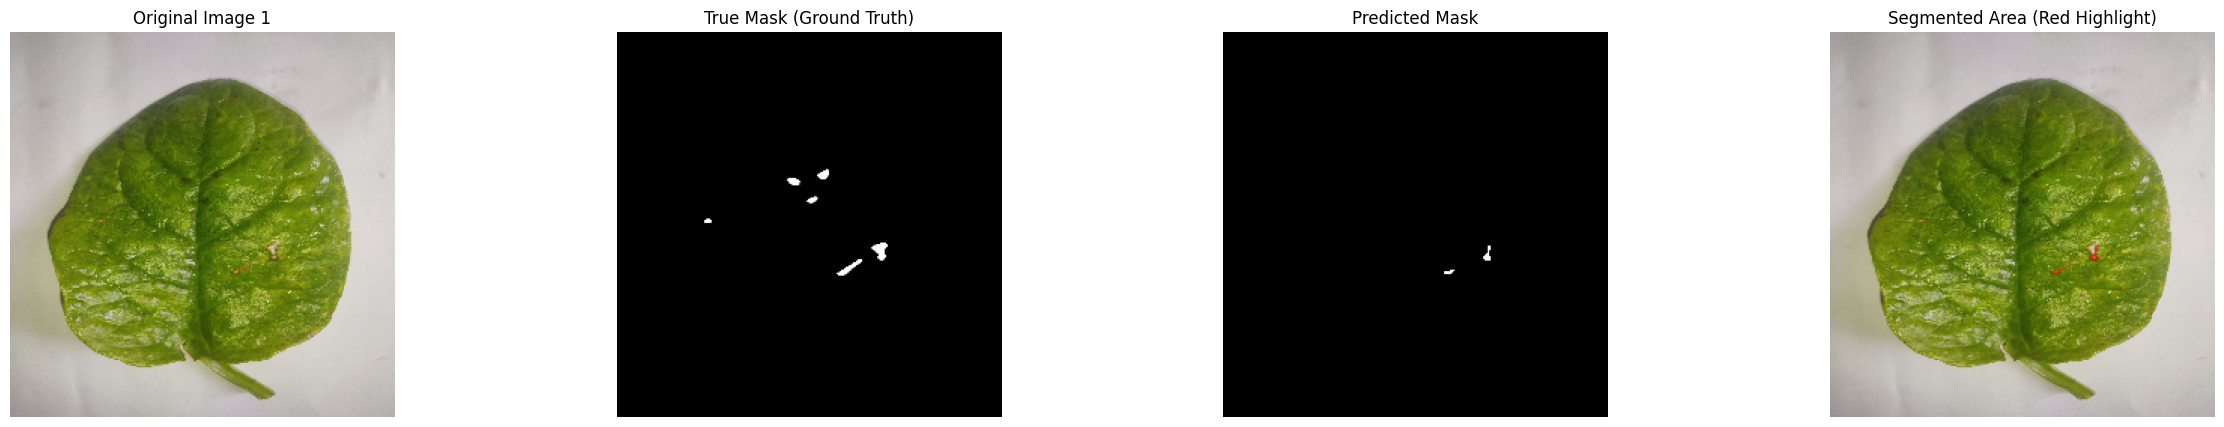

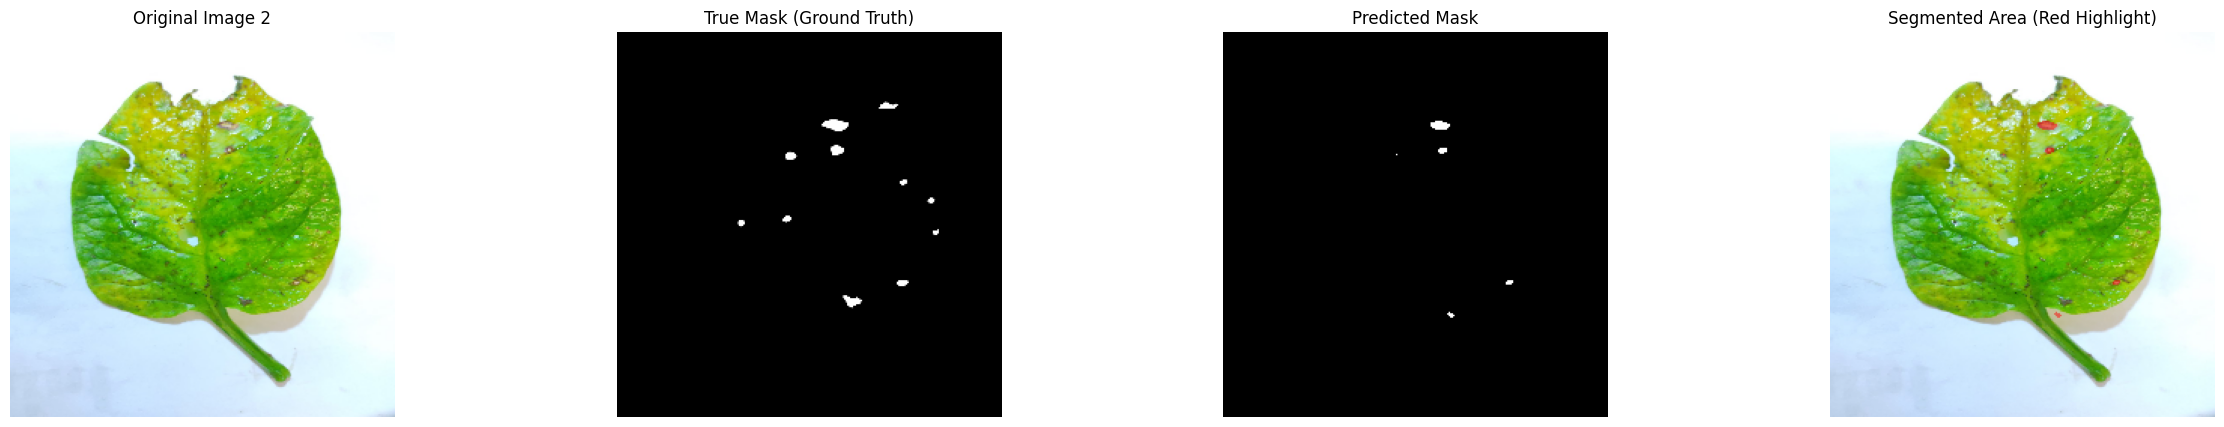

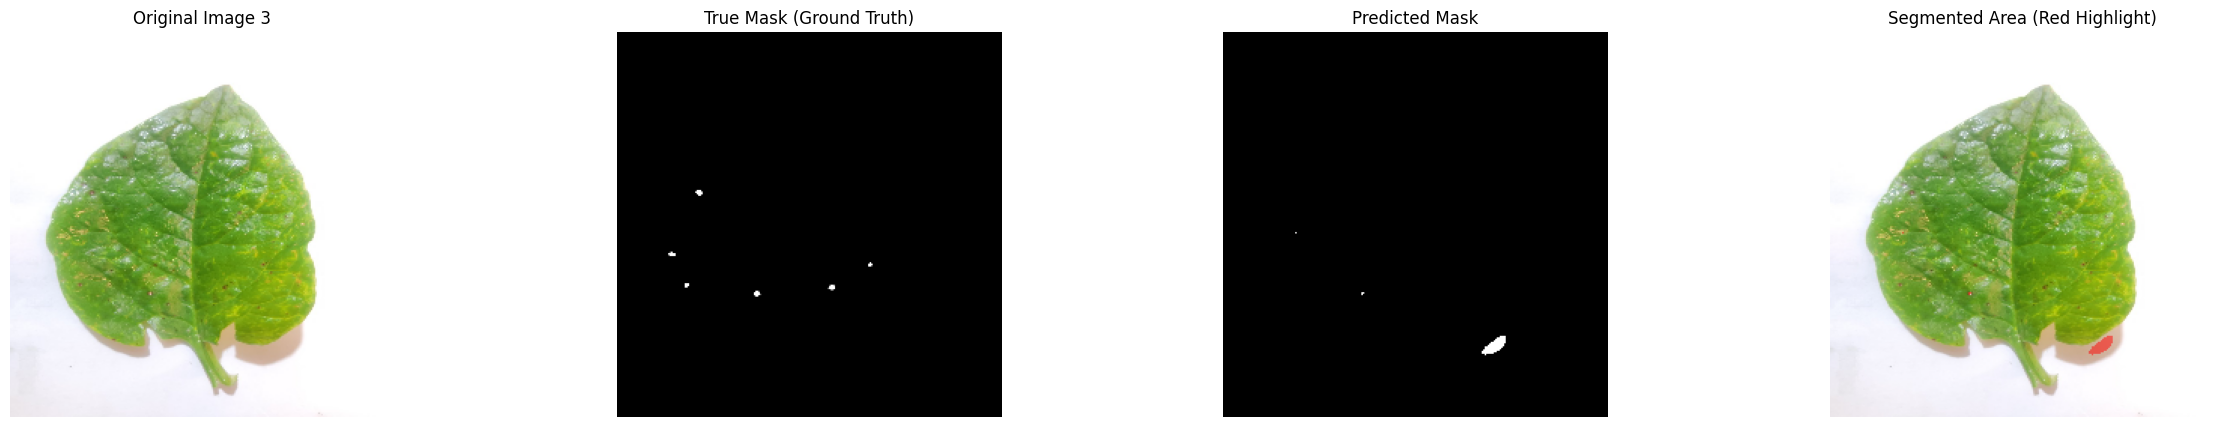

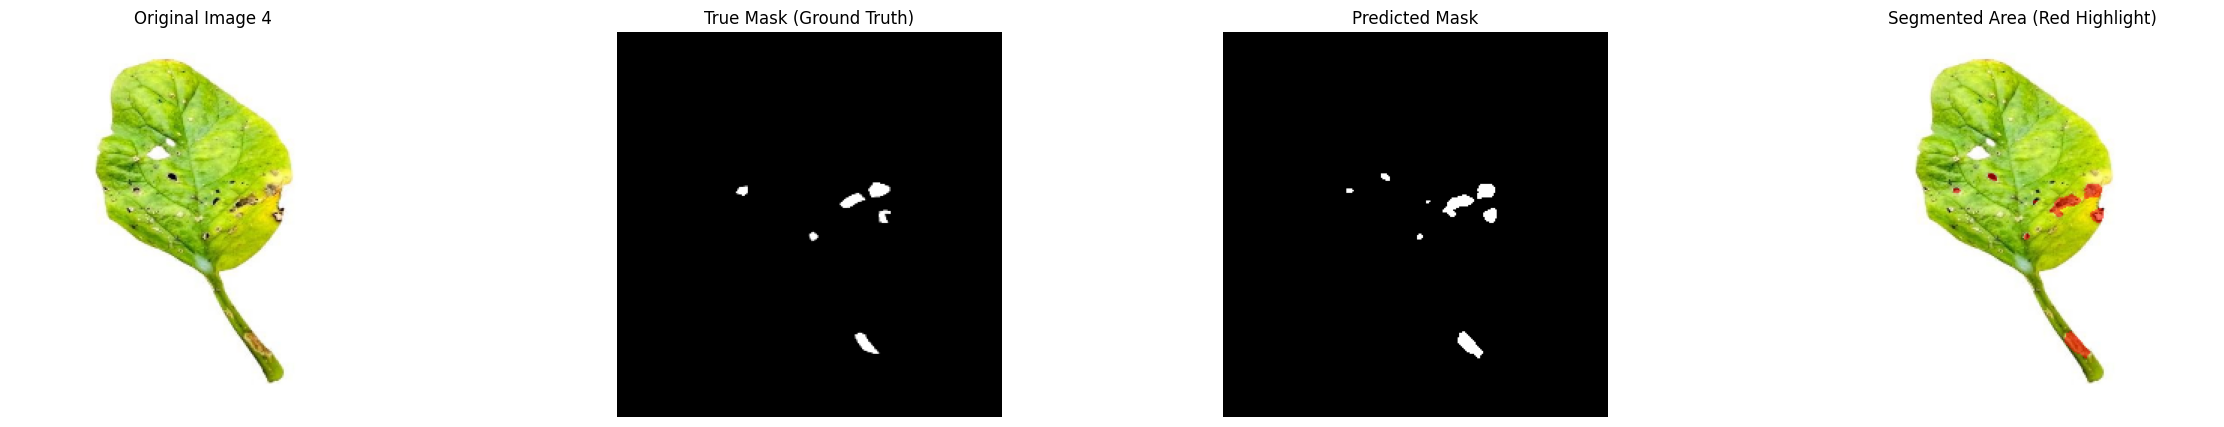

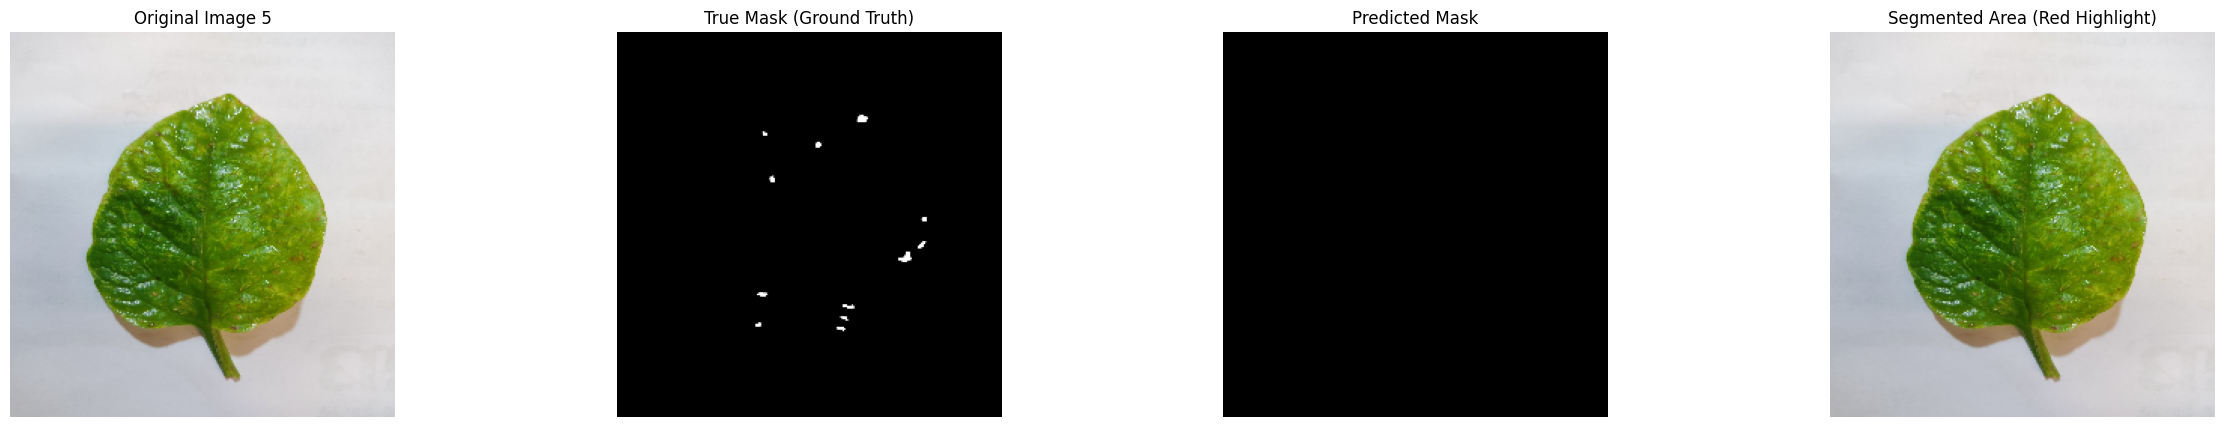

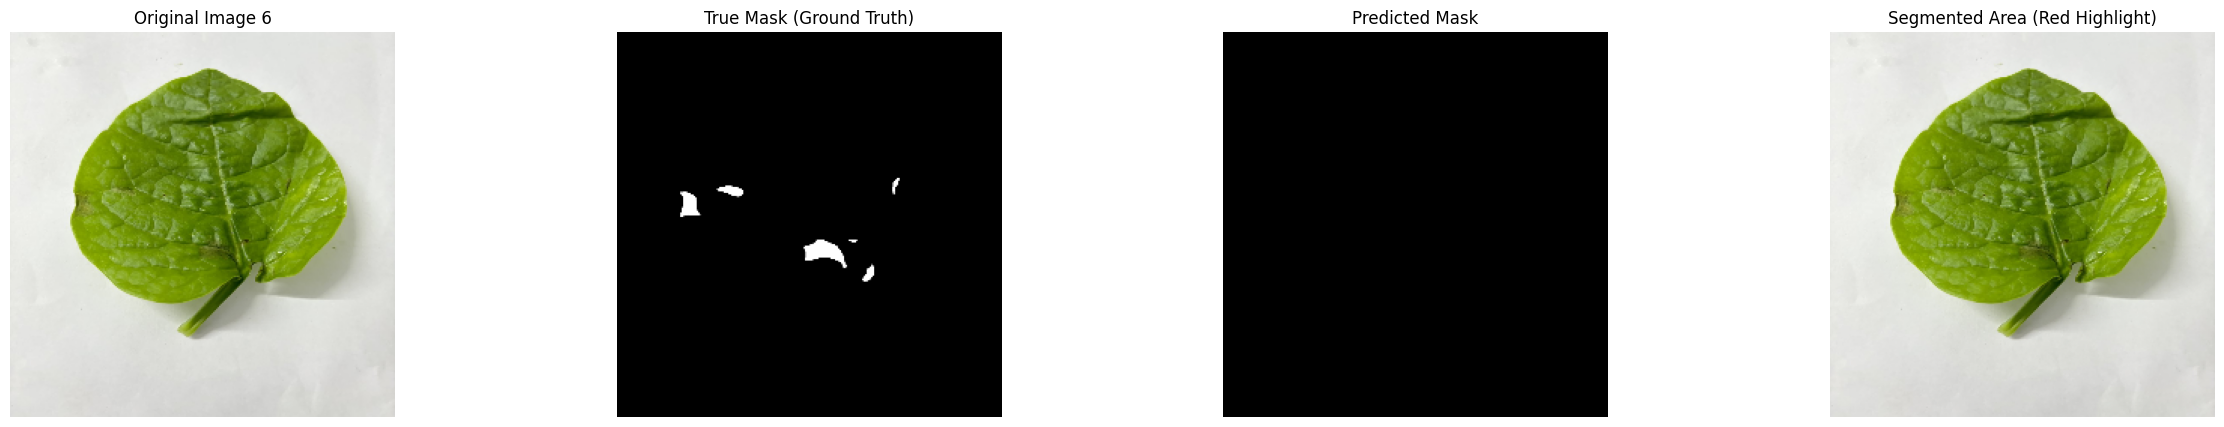

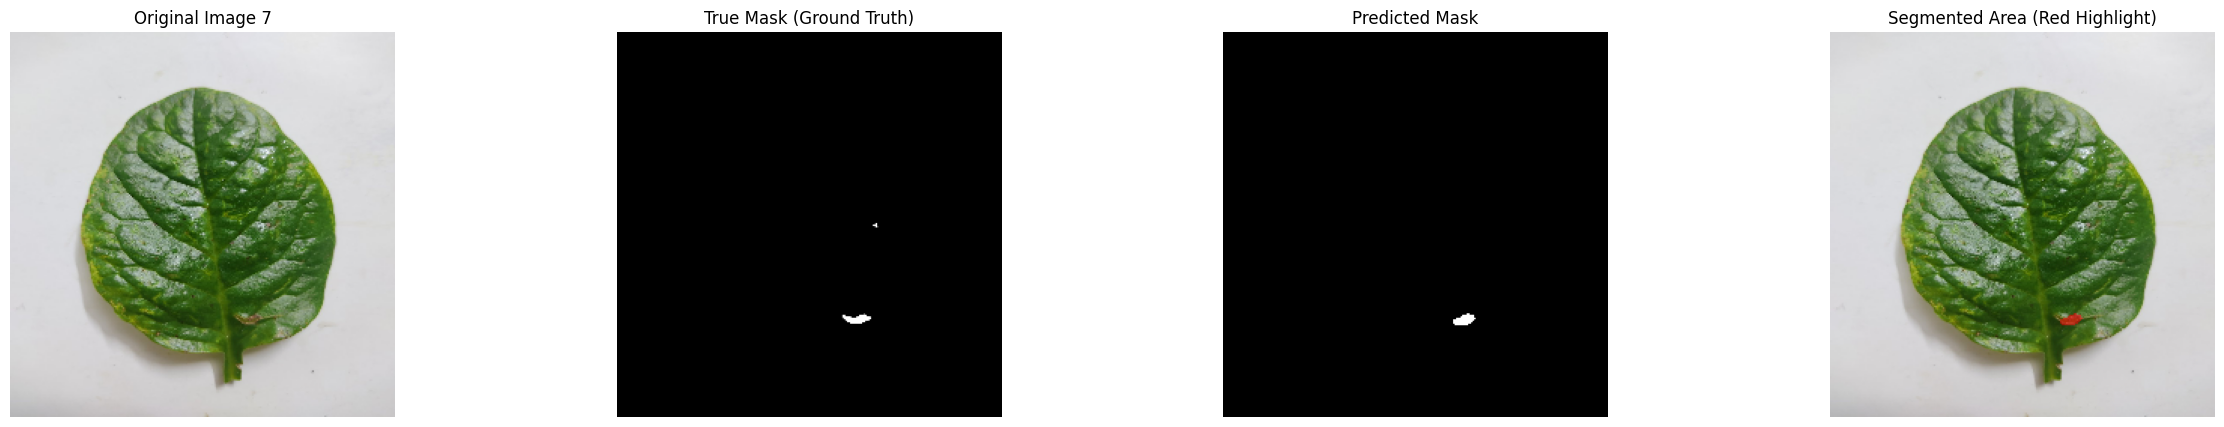

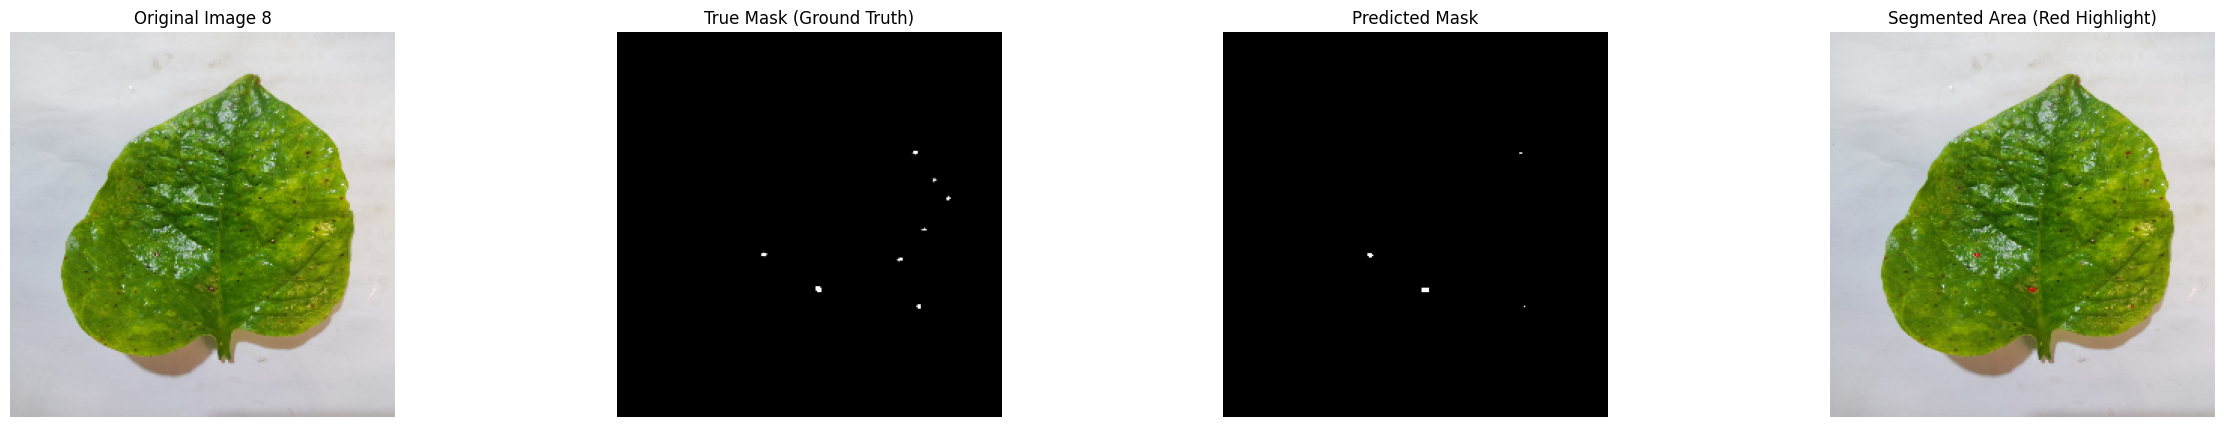

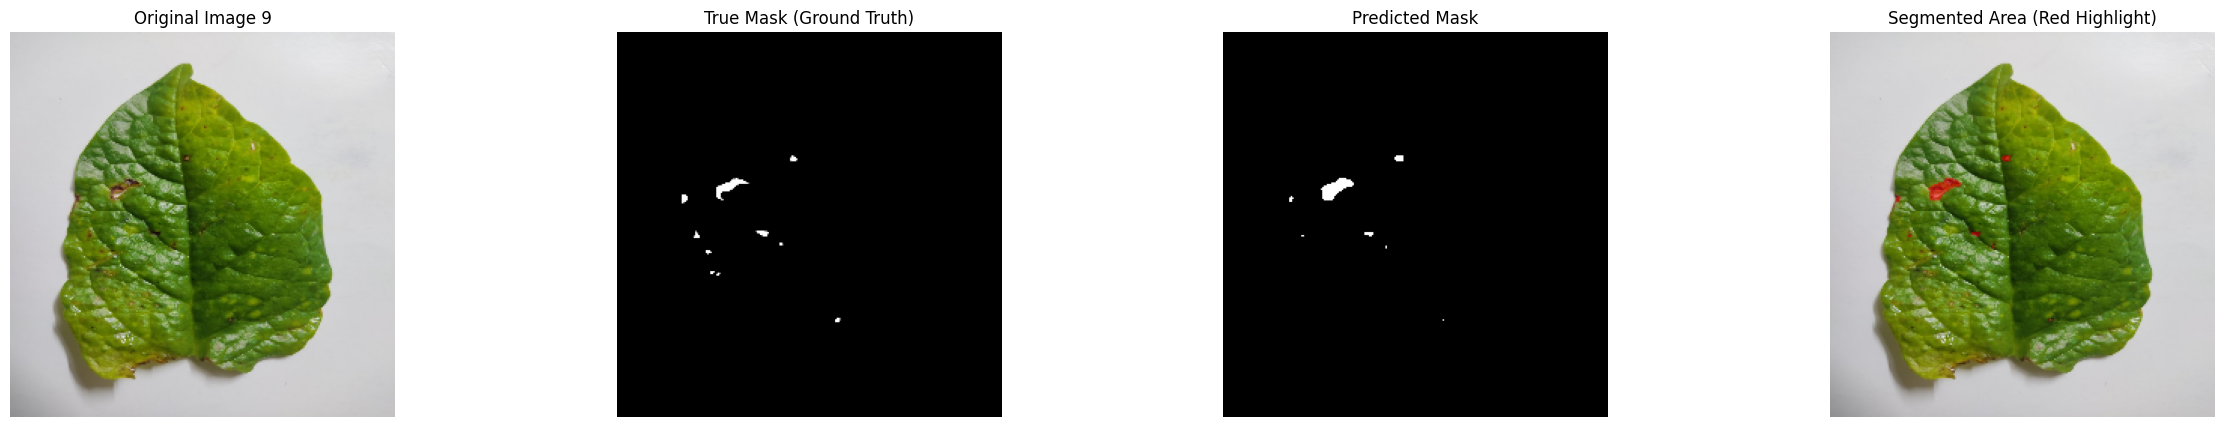

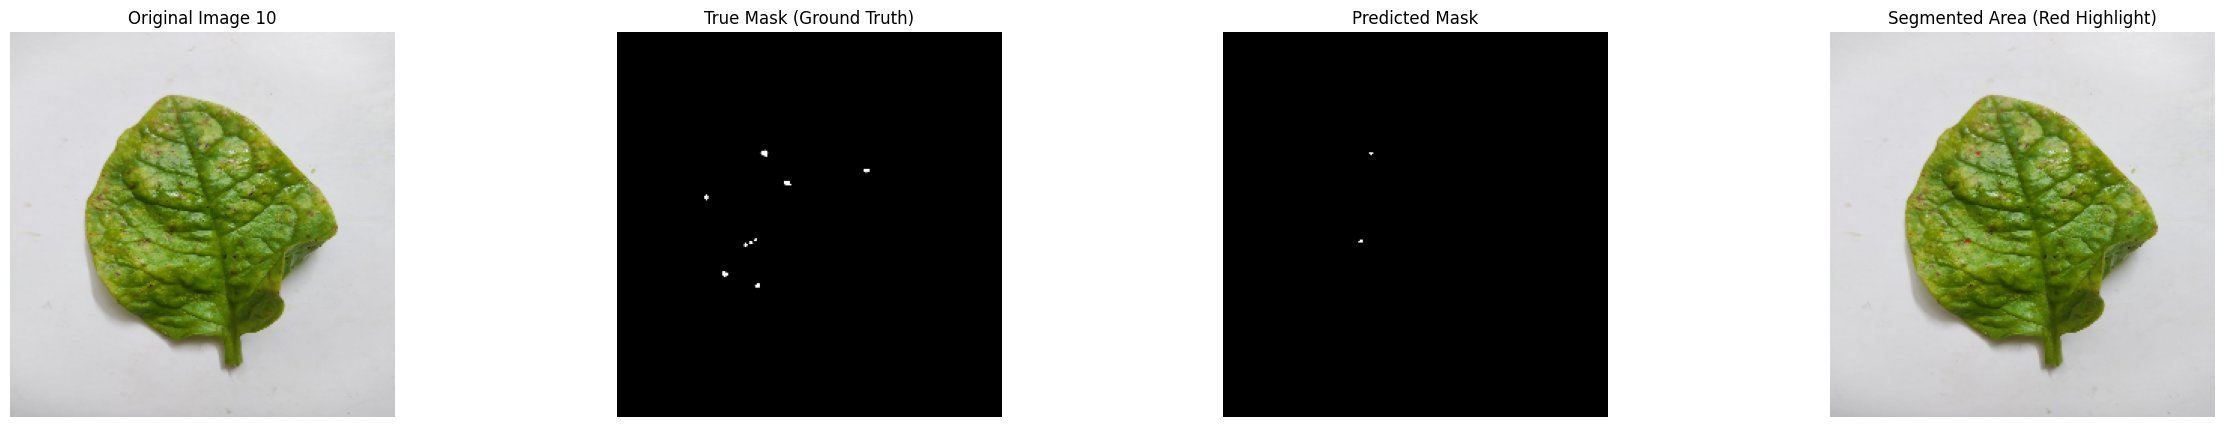

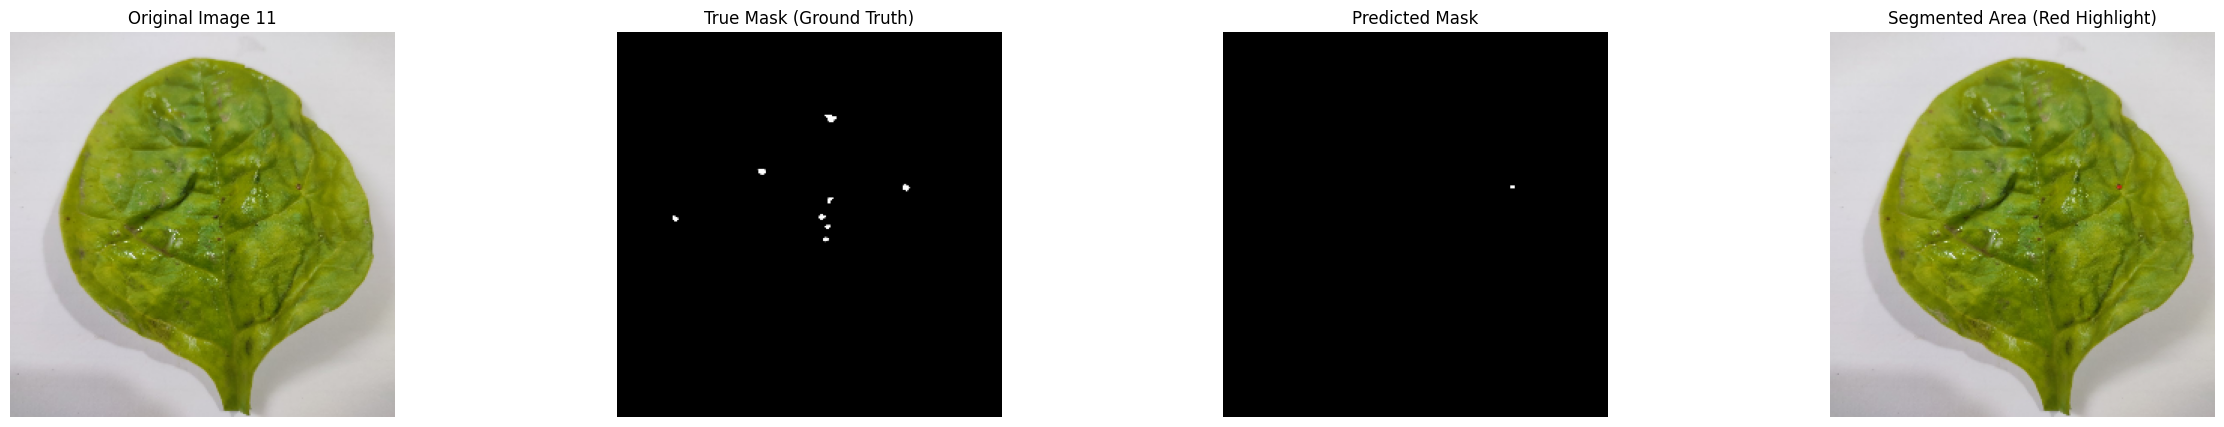

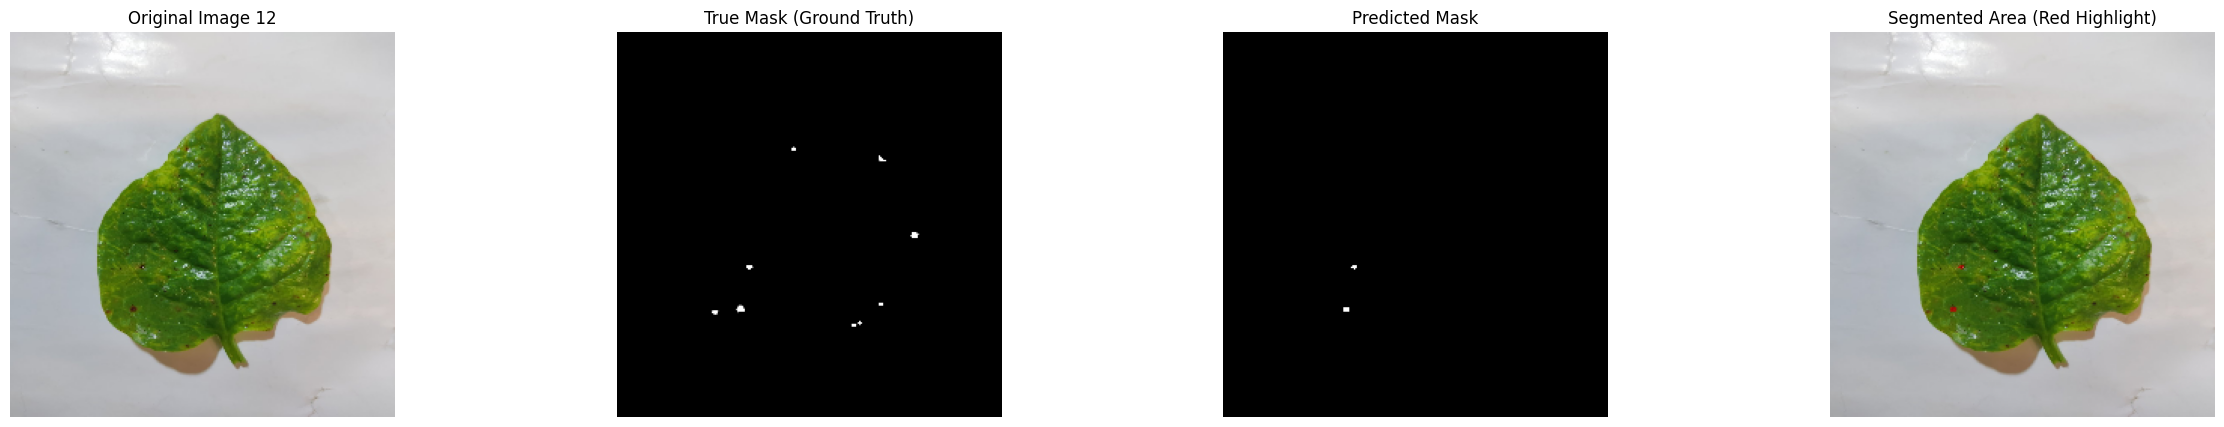

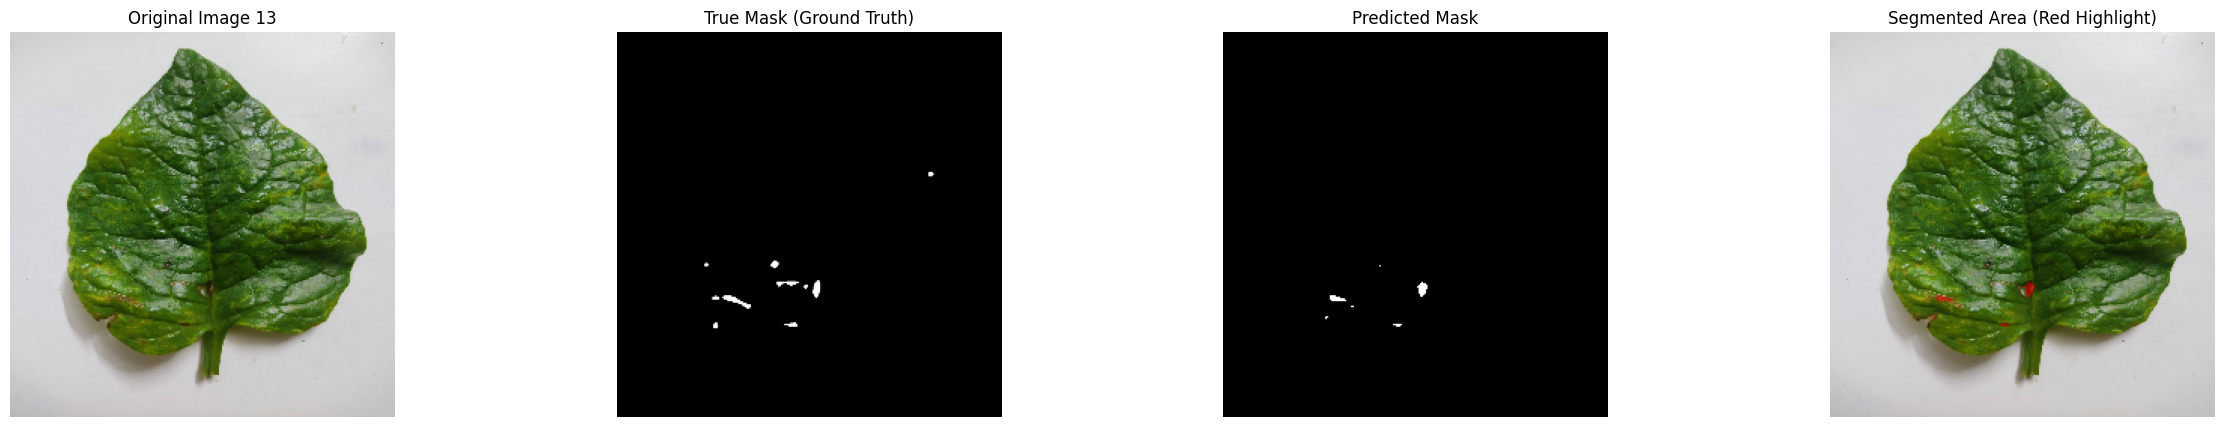

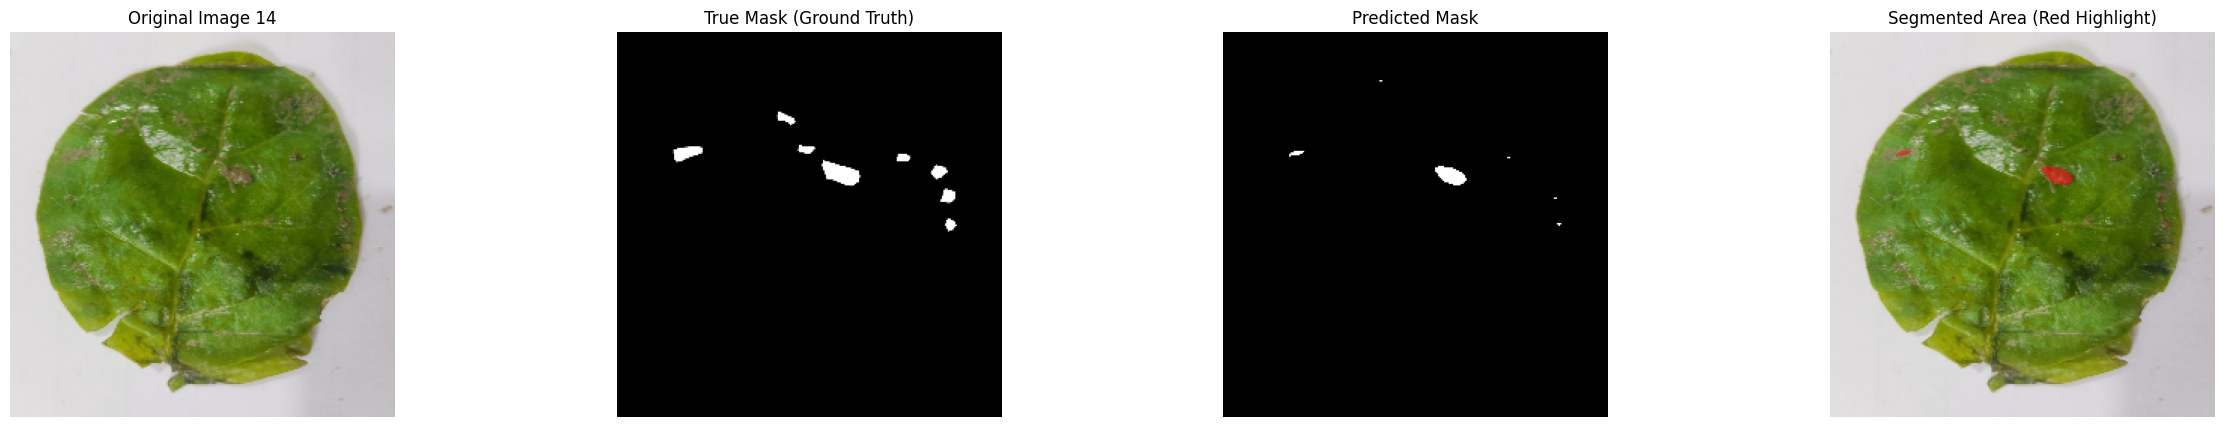

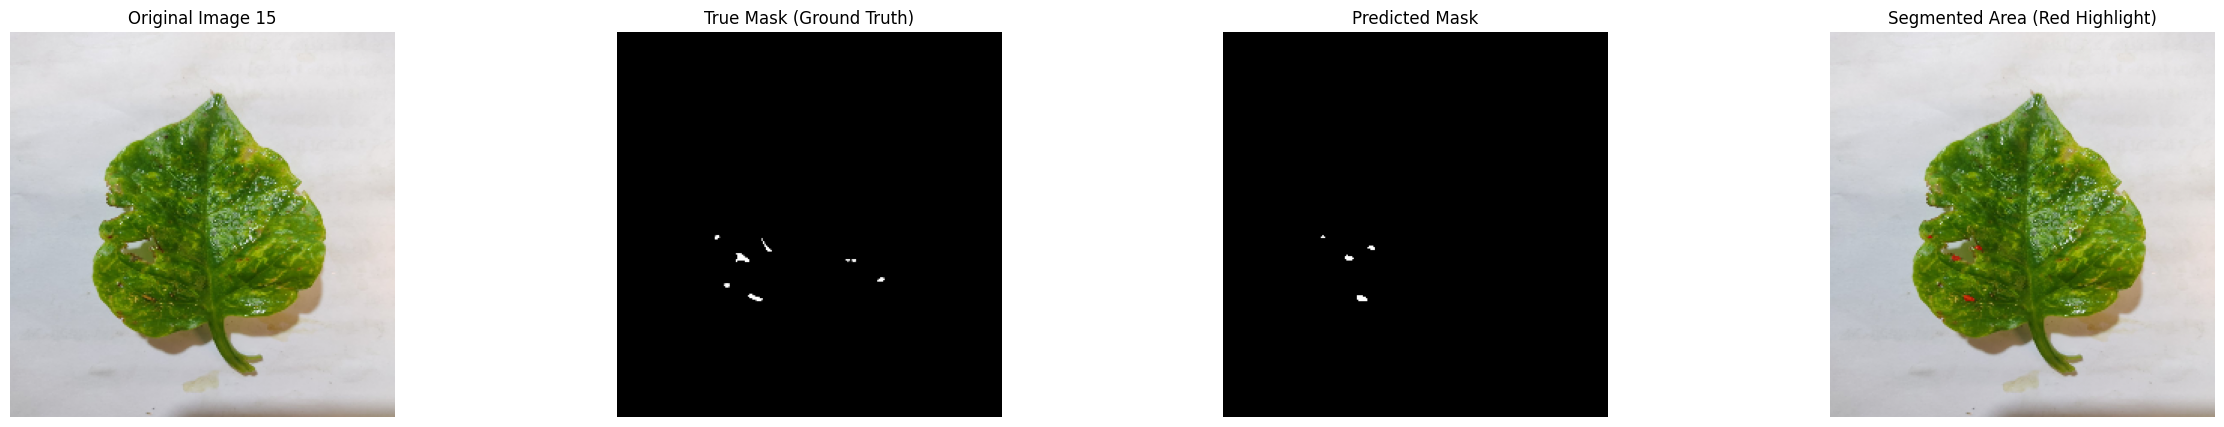

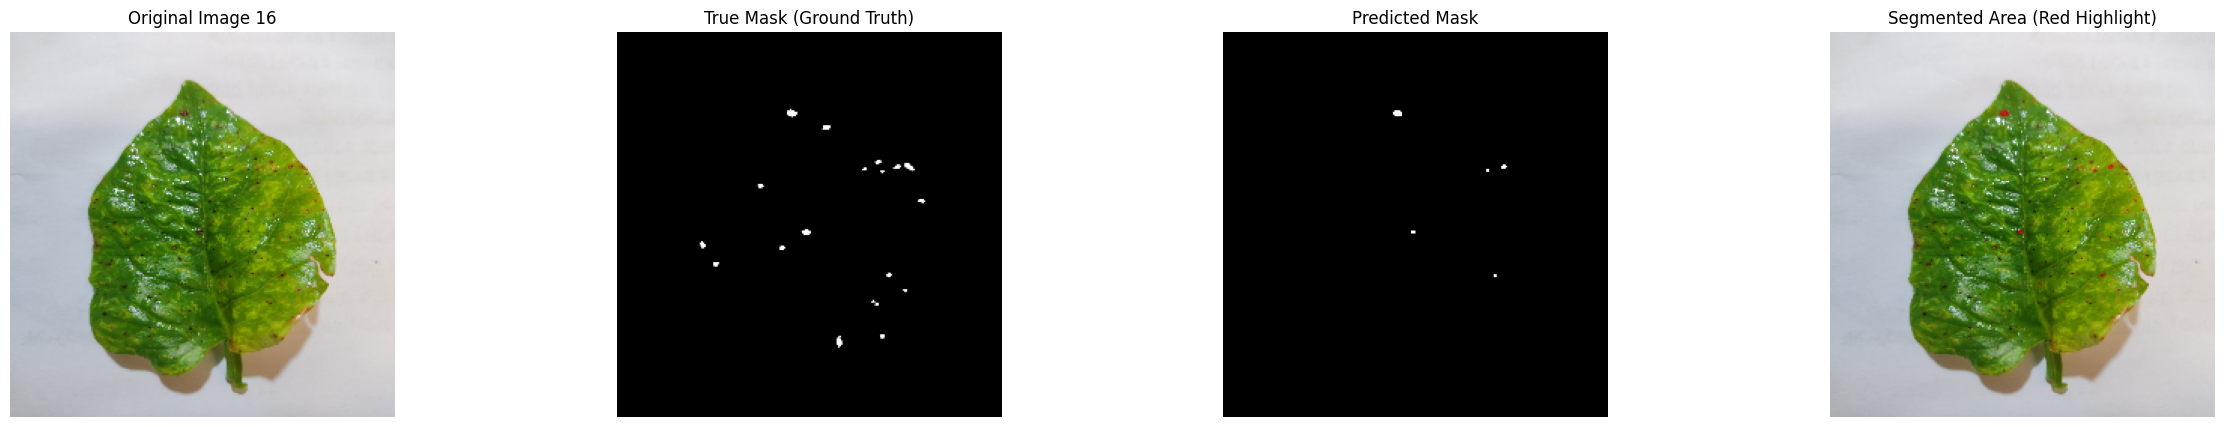

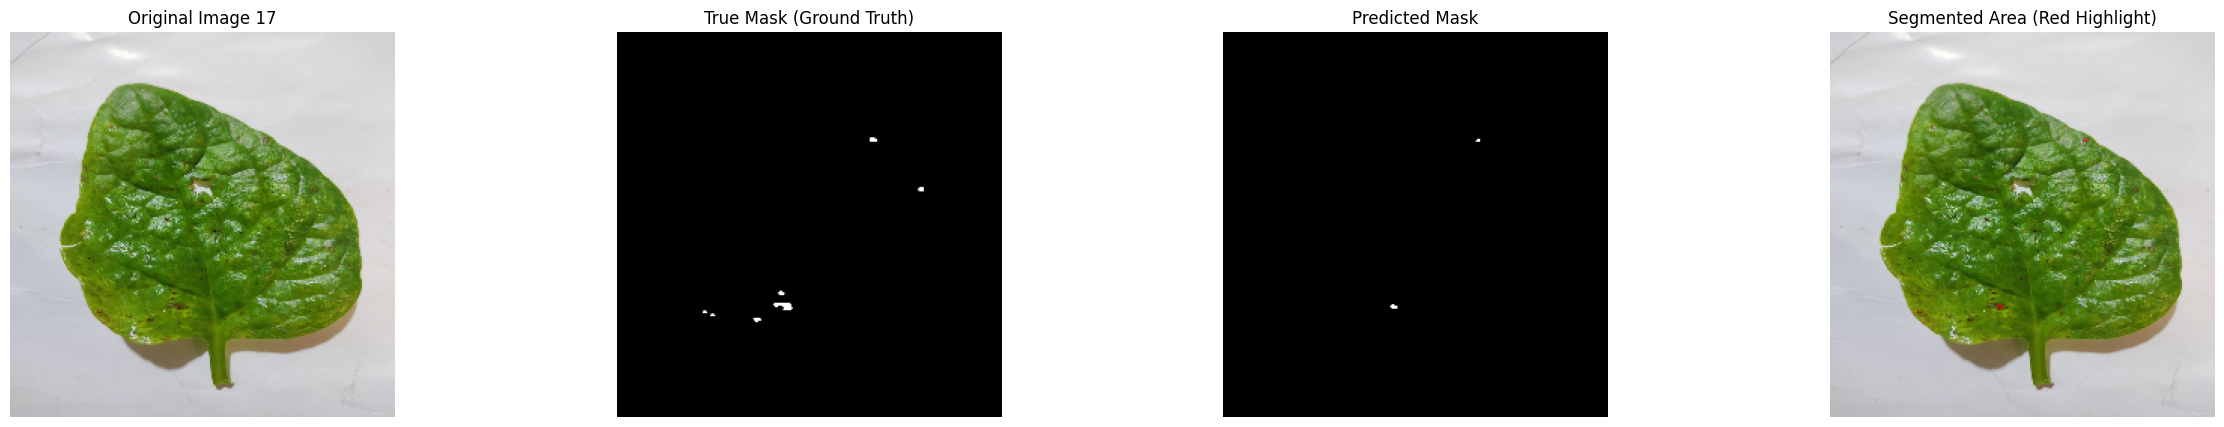

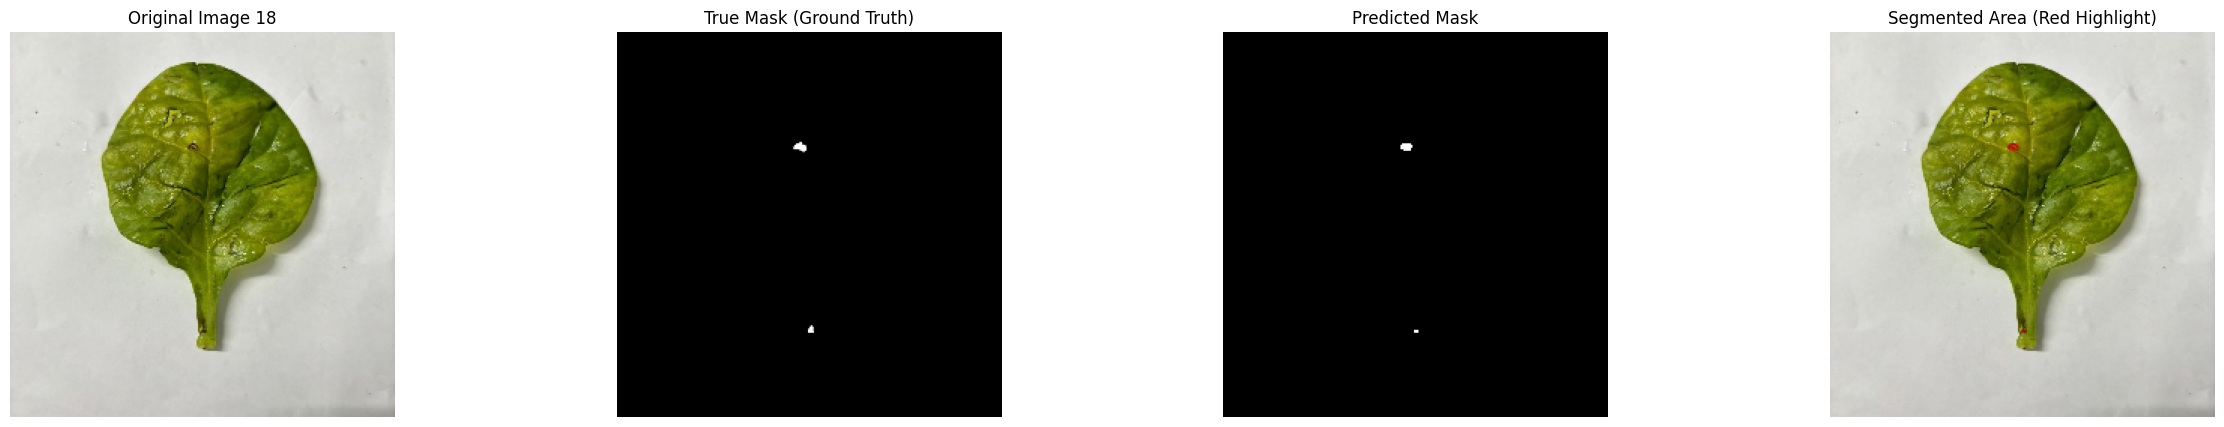

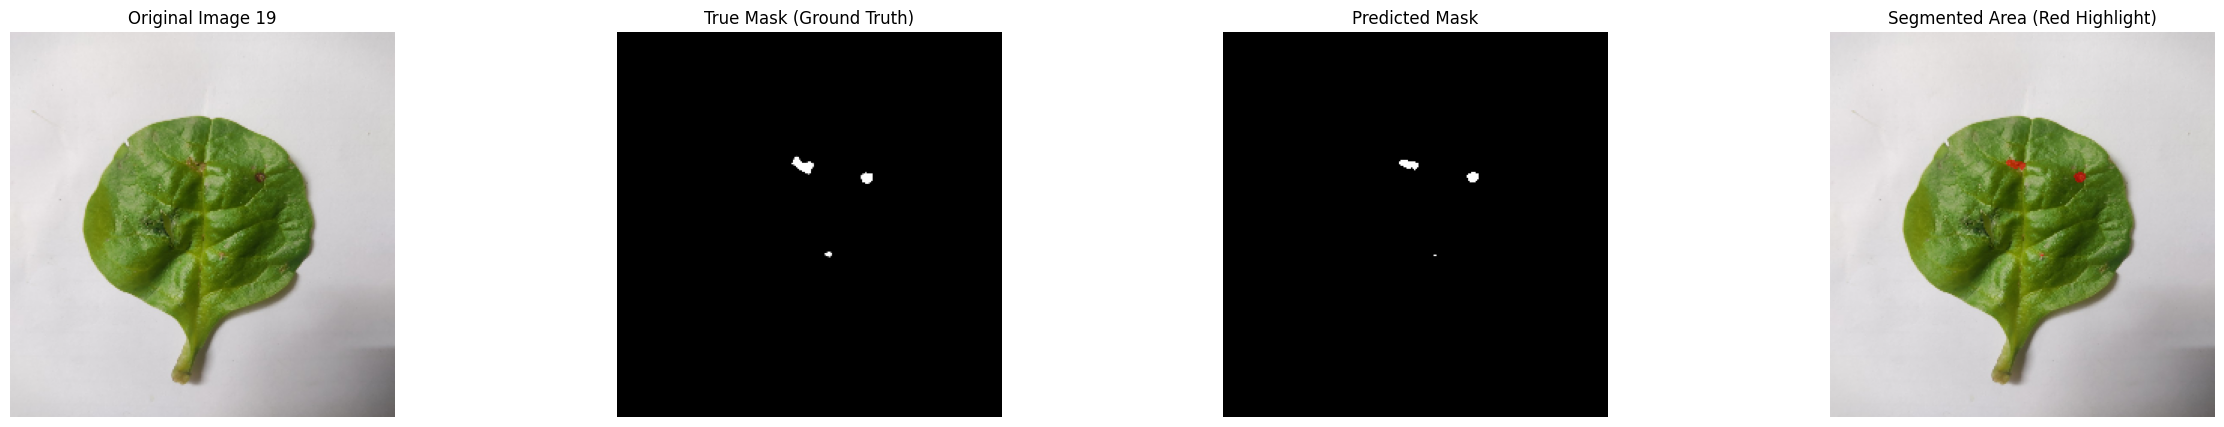

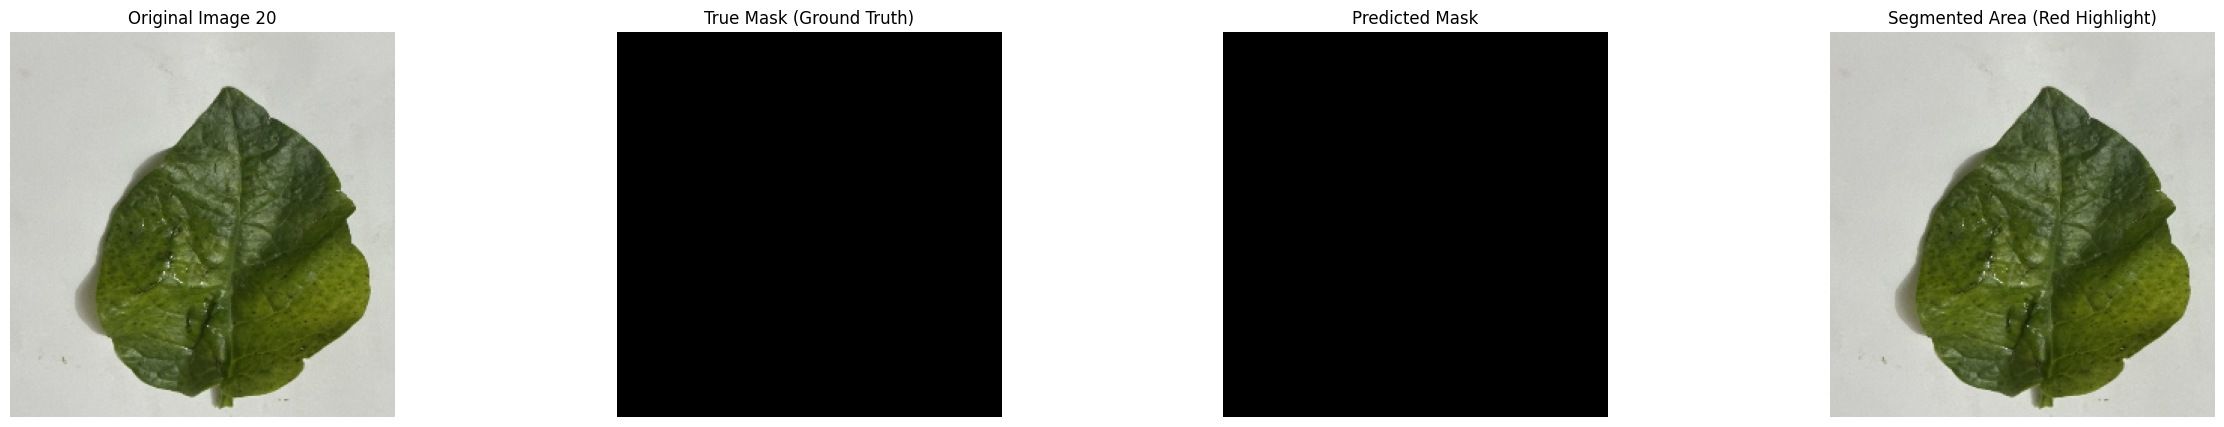

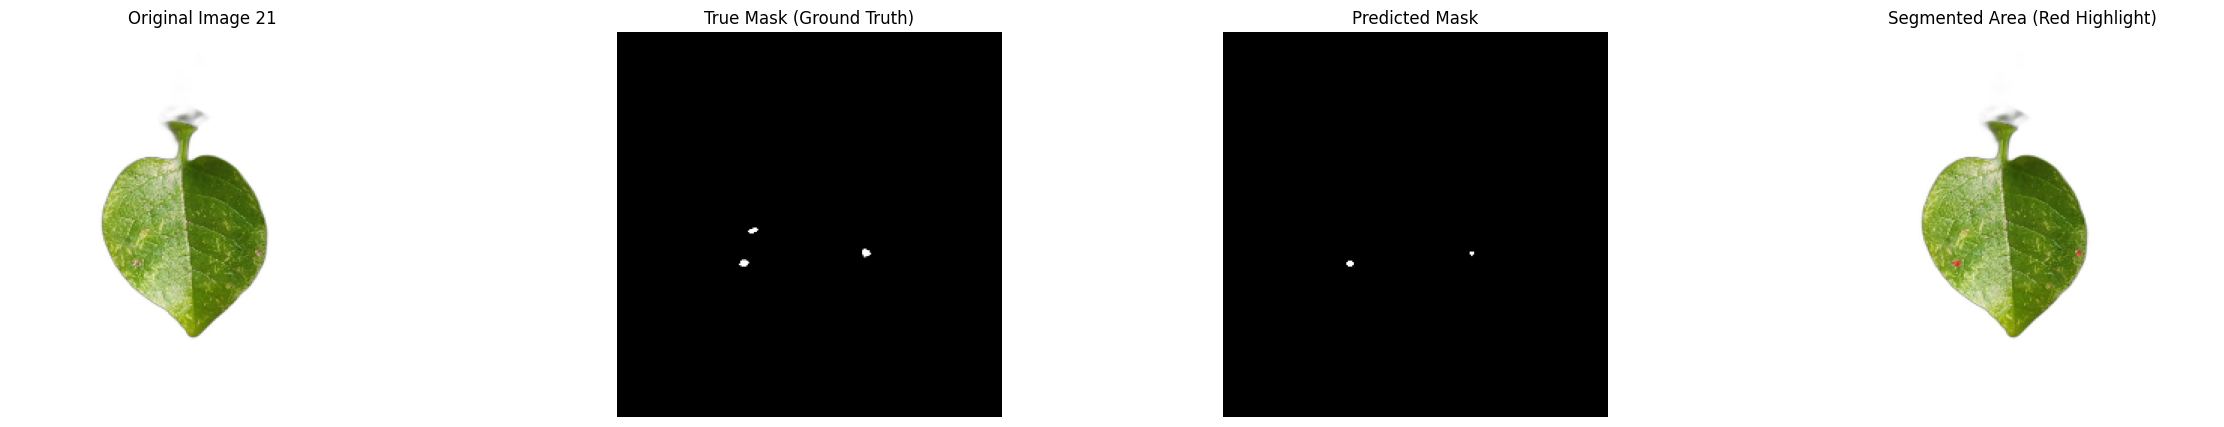

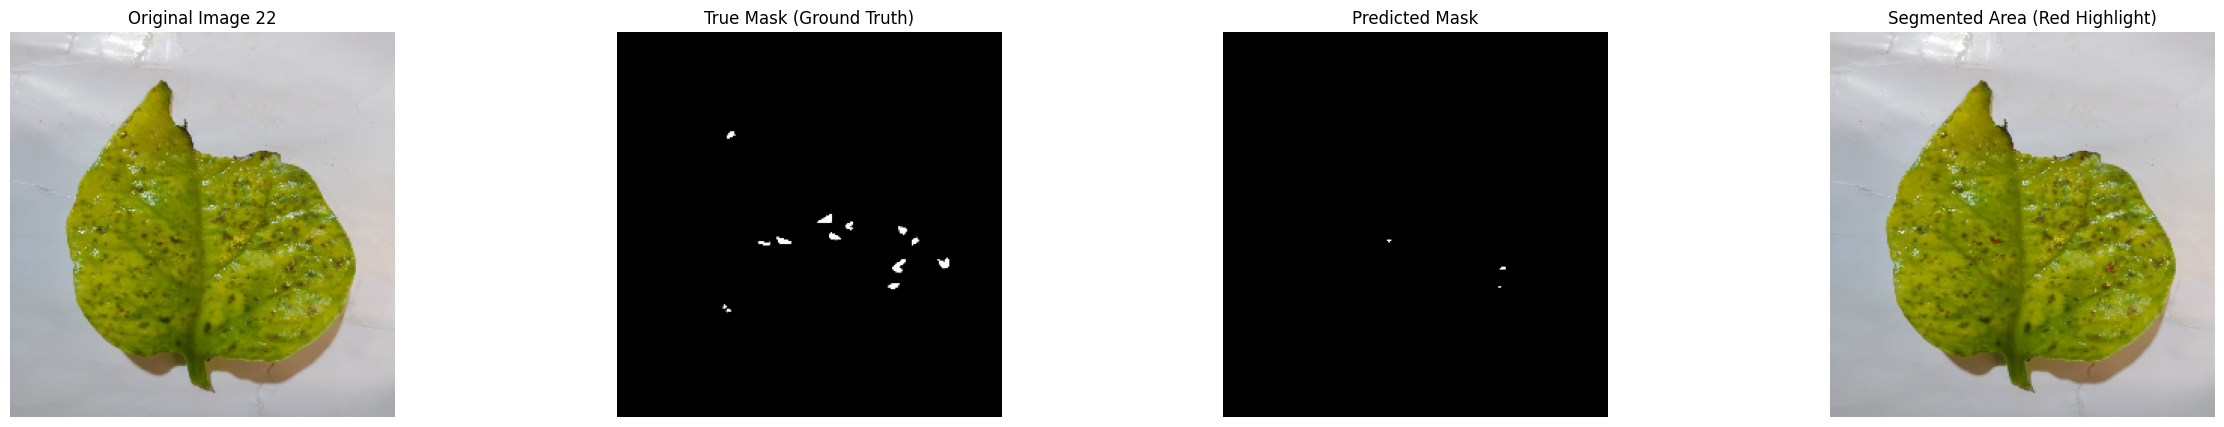

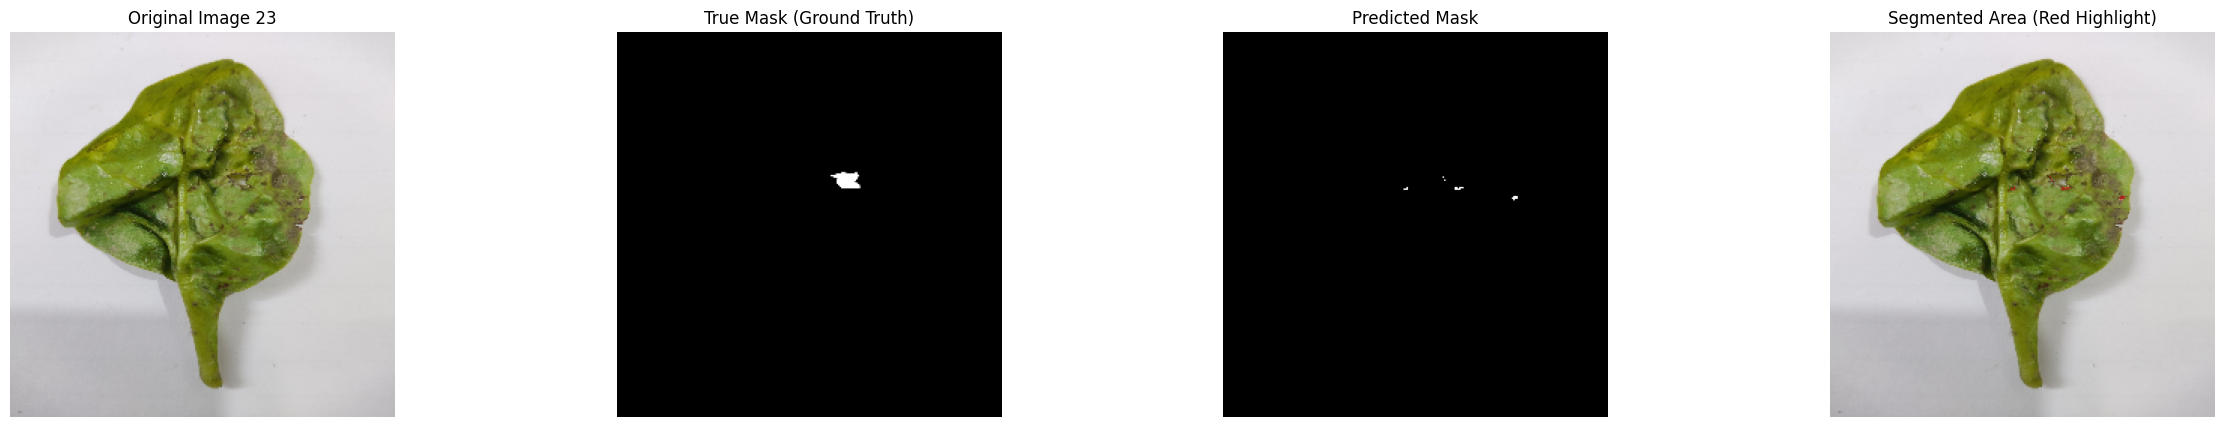

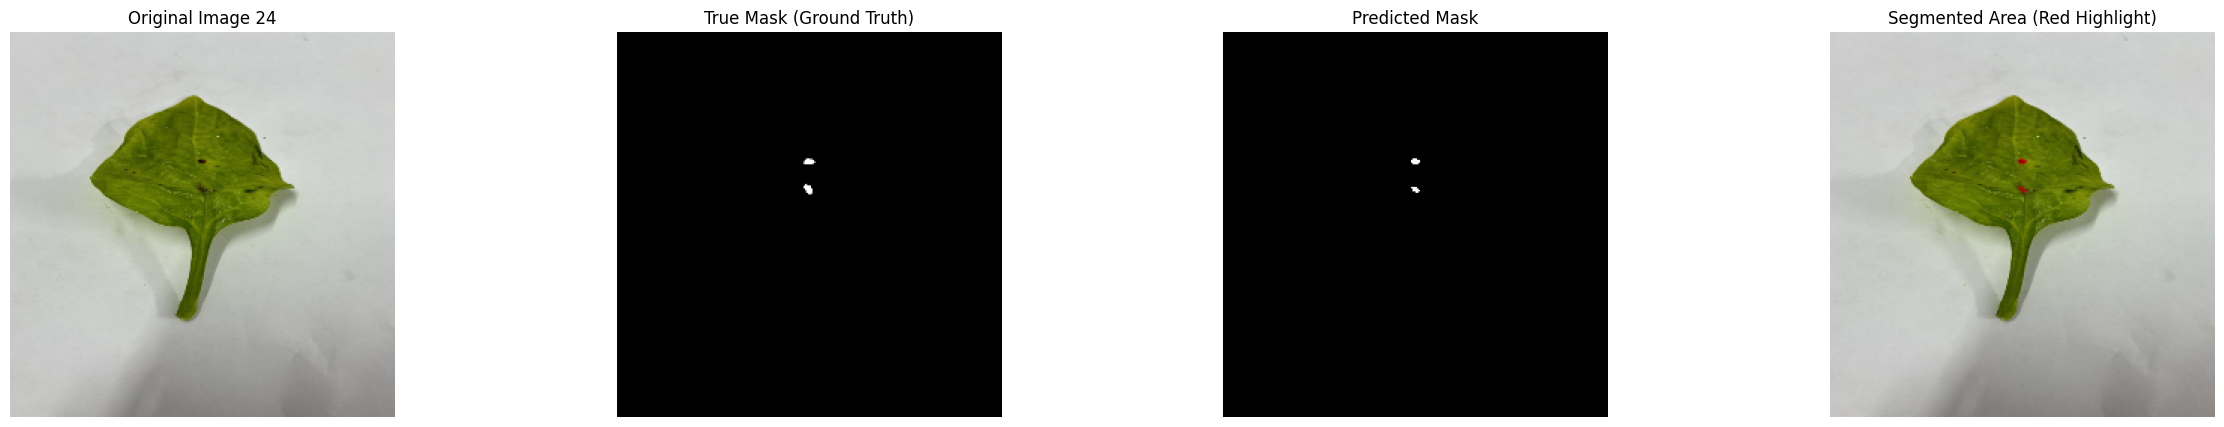

Hello world.


In [24]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

def visualize_results(images, y_test, predicted_masks):
    for i in range(0,len(images)):
        img = images[i]
        true_mask = y_test[i].squeeze()
        predicted_mask = predicted_masks[i].squeeze()

        # Binary predicted mask
        pred_bin = (predicted_mask > 0.5).astype(np.uint8)

        # Ensure uint8 image
        img_uint8 = (img * 255).astype(np.uint8) if img.dtype != np.uint8 else img

        # ---- Red Highlight using Predicted Mask ----
        output = img_uint8.copy()
        alpha = 0.5
        red_color = np.array([0, 0, 255])  # BGR red

        output[pred_bin == 1] = (
            img_uint8[pred_bin == 1] * (1 - alpha) + red_color * alpha
        ).astype(np.uint8)

        # ---- Visualization ----
        plt.figure(figsize=(30, 5))

        plt.subplot(1, 4, 1)
        plt.imshow(cv2.cvtColor(img_uint8, cv2.COLOR_BGR2RGB))
        plt.title('Original Image '+str(i+1))
        plt.axis('off')

        plt.subplot(1, 4, 2)
        plt.imshow(true_mask, cmap='gray')
        plt.title('True Mask (Ground Truth)')
        plt.axis('off')

        plt.subplot(1, 4, 3)
        plt.imshow(predicted_mask, cmap='gray')
        plt.title('Predicted Mask')
        plt.axis('off')

        plt.subplot(1, 4, 4)
        plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
        plt.title('Segmented Area (Red Highlight)')
        plt.axis('off')

        plt.show()

visualize_results(X_test, Y_test, predicted_masks)
print("Hello world.")

In [25]:
import os
import cv2
import numpy as np
import zipfile
from scipy import stats
from skimage.segmentation import find_boundaries

# ===============================
# Paths
# ===============================
BASE_DIR = "/kaggle/working/segmentation_results"

dirs = {
    "original": os.path.join(BASE_DIR, "original_images"),
    "true": os.path.join(BASE_DIR, "true_masks"),
    "pred": os.path.join(BASE_DIR, "predicted_masks"),
    "red": os.path.join(BASE_DIR, "red_highlighted")
}

for d in dirs.values():
    os.makedirs(d, exist_ok=True)

# ===============================
# Save images
# ===============================
alpha = 0.5
red_color = np.array([0, 0, 255])  # BGR

for i in range(len(X_test)):
    # ---- Original Image ----
    img = X_test[i]
    img_uint8 = (img * 255).astype(np.uint8) if img.dtype != np.uint8 else img
    cv2.imwrite(f"{dirs['original']}/original_image_{i+1}.jpg", img_uint8)

    # ---- True Mask ----
    true_mask = Y_test[i].squeeze()
    true_mask_uint8 = (true_mask * 255).astype(np.uint8)
    cv2.imwrite(f"{dirs['true']}/true_mask_{i+1}.png", true_mask_uint8)

    # ---- Predicted Mask ----
    pred_mask = (predicted_masks[i].squeeze() > 0.5).astype(np.uint8)
    pred_mask_uint8 = pred_mask * 255
    cv2.imwrite(f"{dirs['pred']}/predicted_mask_{i+1}.png", pred_mask_uint8)

    # ---- Red Highlighted Segmentation ----
    output = img_uint8.copy()
    output[pred_mask == 1] = (
        img_uint8[pred_mask == 1] * (1 - alpha) + red_color * alpha
    ).astype(np.uint8)

    cv2.imwrite(f"{dirs['red']}/red_highlight_{i+1}.jpg", output)

# ===============================
# Zip folders
# ===============================
def zip_folder(folder_path, zip_name):
    zip_path = os.path.join(BASE_DIR, zip_name)
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, _, files in os.walk(folder_path):
            for file in files:
                full_path = os.path.join(root, file)
                zipf.write(full_path, arcname=file)

zip_folder(dirs['original'], "original_image.zip")
zip_folder(dirs['true'], "true_mask.zip")
zip_folder(dirs['pred'], "predicted_mask.zip")
zip_folder(dirs['red'], "red_highligh_segmented_area.zip")

print("✅ All ZIP files created successfully!")

✅ All ZIP files created successfully!


In [26]:
dice, iou, precision, recall, f1_score , total_iou, total_dice, total_precision,total_recall, total_f1_score = 0,0,0,0,0,0,0,0,0, 0
for i in range(0, len(Y_test)):
    true_mask = Y_test[i].squeeze()
    predicted_mask = predicted_masks[i].squeeze()

    true_mask = (true_mask > 0.5).astype(np.float32)
    predicted_mask = (predicted_mask > 0.5).astype(np.float32)

    true_positives = np.sum(true_mask * predicted_mask)
    union = np.sum(true_mask) + np.sum(predicted_mask) - true_positives
    false_positives = np.sum(predicted_mask) - true_positives
    false_negatives = np.sum(true_mask) - true_positives

    epsilon = 1e-7

    dice = (2. * true_positives + epsilon ) / (np.sum(true_mask) + np.sum(predicted_mask) + epsilon )
    total_dice = total_dice + dice
    iou = (true_positives + epsilon) / (union + epsilon )
    total_iou = total_iou + iou
    precision = (true_positives + epsilon ) / (true_positives + false_positives + epsilon )
    total_precision = total_precision + precision
    recall = (true_positives + epsilon) / (true_positives + false_negatives + epsilon )
    total_recall = total_recall + recall
    f1_score = dice
    total_f1_score = total_f1_score + f1_score


print("mean dice ", total_dice/len(Y_test))
print("mean iou ", total_iou/len(Y_test))
print("mean precision ", total_precision/len(Y_test))
print("mean recall ", total_recall/len(Y_test))
print("mean f1 score ", total_f1_score/len(Y_test))

mean dice  0.41748321162843044
mean iou  0.3093129055953821
mean precision  0.8325341868583863
mean recall  0.3426666369107955
mean f1 score  0.41748321162843044


In [ ]:
while(True):
    a = 0